In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# display settings
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

In [4]:
df = pd.read_csv("Loan.csv")   

df.head()

,Unnamed: 0,id,year,loan_limit,gender,approv_in_adv,loan_type,loan_purpose,credit_worthiness,open_credit,business_or_commercial,loan_amount,rate_of_interest,interest_rate_spread,upfront_charges,term,neg_ammortization,interest_only,lump_sum_payment,property_value,construction_type,occupancy_type,secured_by,total_units,income,credit_type,credit_score,co-applicant_credit_type,age,submission_of_application,ltv,region,security_type,status,dtir1,high_interest_rate,senior_age
0,126324,151214,2019,ncf,Male,nopre,type1,p3,l1,nopc,nob/c,986500,4.125,0.6174,9825.00,360.0,neg_amm,not_int,not_lpsm,1408000.0,sb,pr,home,1U,13380.0,CIB,864,EXP,35-44,to_inst,70.063920,North,direct,0,42.0,1,0
1,13385,38275,2019,cf,Joint,nopre,type1,p4,l1,nopc,nob/c,406500,3.625,-0.1990,1100.00,360.0,not_neg,not_int,not_lpsm,1008000.0,sb,pr,home,1U,5640.0,CRIF,505,EXP,>74,not_inst,40.327381,North,direct,0,40.0,0,1
2,98606,123496,2019,cf,Sex Not Available,nopre,type1,p3,l1,nopc,nob/c,166500,4.250,0.7779,2379.51,180.0,not_neg,not_int,not_lpsm,338000.0,sb,pr,home,1U,4740.0,CRIF,829,CIB,55-64,to_inst,49.260355,south,direct,0,29.0,1,1
3,7184,32074,2019,cf,Female,nopre,type1,p3,l1,nopc,nob/c,206500,5.625,1.1174,6117.50,360.0,not_neg,not_int,not_lpsm,278000.0,sb,pr,home,1U,3780.0,EXP,763,CIB,35-44,to_inst,74.280576,North,direct,0,44.0,1,0
4,120745,145635,2019,cf,Male,nopre,type1,p1,l1,nopc,nob/c,166500,3.500,0.1533,779.88,360.0,not_neg,not_int,not_lpsm,168000.0,sb,pr,home,1U,2400.0,CIB,886,CIB,35-44,not_inst,99.107143,North,direct,0,42.0,0,0


In [3]:
print("Shape of dataset:", df.shape)
print("\nColumns:\n", df.columns.tolist())
print("\nData types:\n")
print(df.dtypes)

Shape of dataset: (148670, 37)

Columns:
 ['Unnamed: 0', 'id', 'year', 'loan_limit', 'gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'credit_worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'interest_rate_spread', 'upfront_charges', 'term', 'neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'secured_by', 'total_units', 'income', 'credit_type', 'credit_score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'ltv', 'region', 'security_type', 'status', 'dtir1', 'high_interest_rate', 'senior_age']

Data types:

Unnamed: 0                     int64
id                             int64
year                           int64
loan_limit                    object
gender                        object
approv_in_adv                 object
loan_type                     object
loan_purpose                  object
credit_worthiness             object
open_credit               

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 37 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   Unnamed: 0                 148670 non-null  int64  
 1   id                         148670 non-null  int64  
 2   year                       148670 non-null  int64  
 3   loan_limit                 145326 non-null  object 
 4   gender                     148670 non-null  object 
 5   approv_in_adv              147762 non-null  object 
 6   loan_type                  148670 non-null  object 
 7   loan_purpose               148536 non-null  object 
 8   credit_worthiness          148670 non-null  object 
 9   open_credit                148670 non-null  object 
 10  business_or_commercial     148670 non-null  object 
 11  loan_amount                148670 non-null  int64  
 12  rate_of_interest           148670 non-null  float64
 13  interest_rate_spread       11

In [5]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,148670.0,NaN,NaN,NaN,74334.5,42917.476598,0.0,37167.25,74334.5,111501.75,148669.0
id,148670.0,NaN,NaN,NaN,99224.5,42917.476598,24890.0,62057.25,99224.5,136391.75,173559.0
year,148670.0,NaN,NaN,NaN,2019.0,0.0,2019.0,2019.0,2019.0,2019.0,2019.0
loan_limit,145326,2,cf,135348,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,148670,4,Male,42346,NaN,NaN,NaN,NaN,NaN,NaN,NaN
approv_in_adv,147762,2,nopre,124621,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_type,148670,3,type1,113173,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_purpose,148536,4,p3,55934,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_worthiness,148670,2,l1,142344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
open_credit,148670,2,nopc,148114,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# remove unwanted index column if present
if "Unnamed: 0" in df.columns:
    df.drop("Unnamed: 0", axis=1, inplace=True)

# remove id column if present
if "id" in df.columns:
    df.drop("id", axis=1, inplace=True)

print("Shape after dropping unnecessary columns:", df.shape)

Shape after dropping unnecessary columns: (148670, 35)


In [7]:
missing_values = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percent
}).sort_values(by="Percentage", ascending=False)

missing_df[missing_df["Missing Values"] > 0]

,Missing Values,Percentage
upfront_charges,39642,26.664425
interest_rate_spread,36639,24.644515
dtir1,24121,16.224524
ltv,15098,10.155378
property_value,15098,10.155378
income,9150,6.154571
loan_limit,3344,2.249277
approv_in_adv,908,0.610749
age,200,0.134526
submission_of_application,200,0.134526


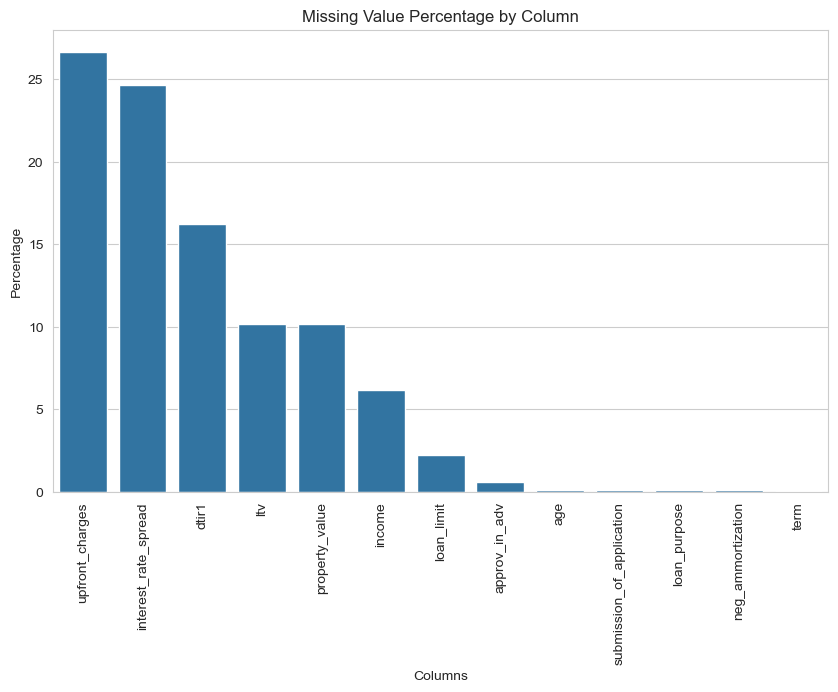

In [8]:
missing_plot = missing_df[missing_df["Missing Values"] > 0]

plt.figure(figsize=(10,6))
sns.barplot(x=missing_plot.index, y=missing_plot["Percentage"])
plt.xticks(rotation=90)
plt.title("Missing Value Percentage by Column")
plt.ylabel("Percentage")
plt.xlabel("Columns")
plt.show()

In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
#  Target variable analysis
print(df["status"].value_counts())
print("\nPercentage:\n", df["status"].value_counts(normalize=True) * 100)

status
0    112031
1     36639
Name: count, dtype: int64

Percentage:
 status
0    75.355485
1    24.644515
Name: proportion, dtype: float64


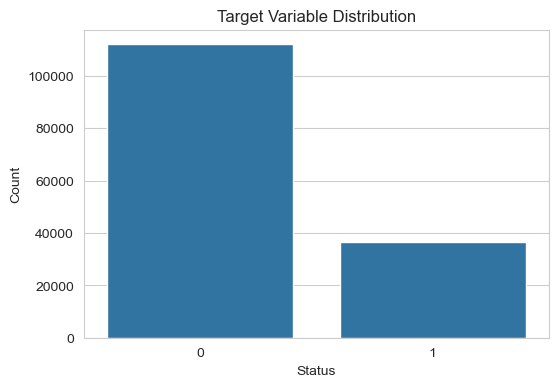

In [11]:
plt.figure(figsize=(6,4))
sns.countplot(x="status", data=df)
plt.title("Target Variable Distribution")
plt.xlabel("Status")
plt.ylabel("Count")
plt.show()

In [12]:
status_percent = df["status"].value_counts(normalize=True) * 100
print("0 class percentage:", round(status_percent[0], 2), "%")
print("1 class percentage:", round(status_percent[1], 2), "%")

0 class percentage: 75.36 %
1 class percentage: 24.64 %


In [13]:
# separting numerical and categorical columns
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()

print("Numerical columns:\n", num_cols)
print("\nCategorical columns:\n", cat_cols)

Numerical columns:
 ['year', 'loan_amount', 'rate_of_interest', 'interest_rate_spread', 'upfront_charges', 'term', 'property_value', 'income', 'credit_score', 'ltv', 'status', 'dtir1', 'high_interest_rate', 'senior_age']

Categorical columns:
 ['loan_limit', 'gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'credit_worthiness', 'open_credit', 'business_or_commercial', 'neg_ammortization', 'interest_only', 'lump_sum_payment', 'construction_type', 'occupancy_type', 'secured_by', 'total_units', 'credit_type', 'co-applicant_credit_type', 'age', 'submission_of_application', 'region', 'security_type']


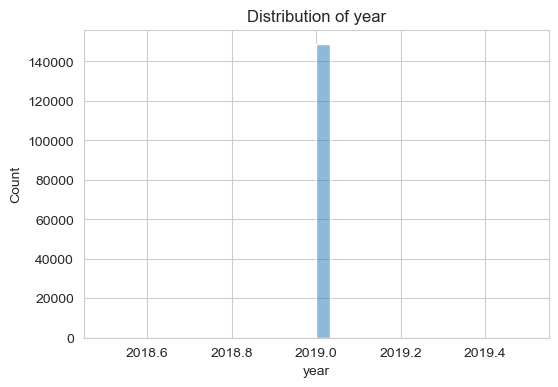

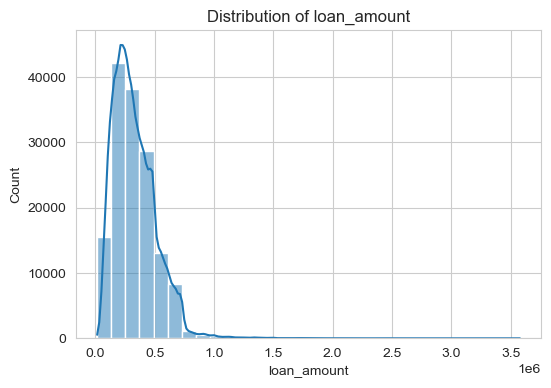

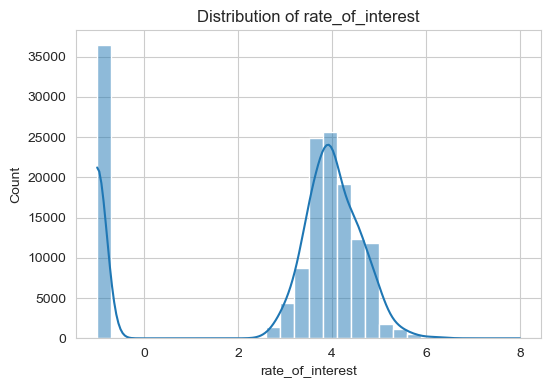

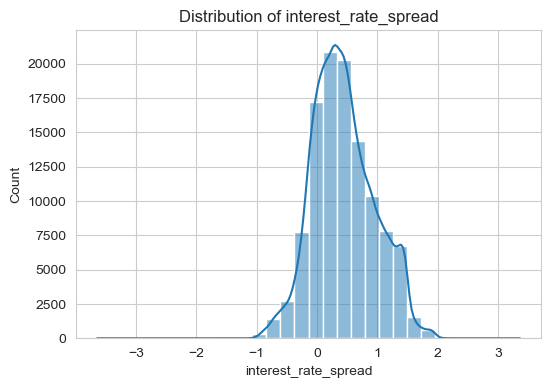

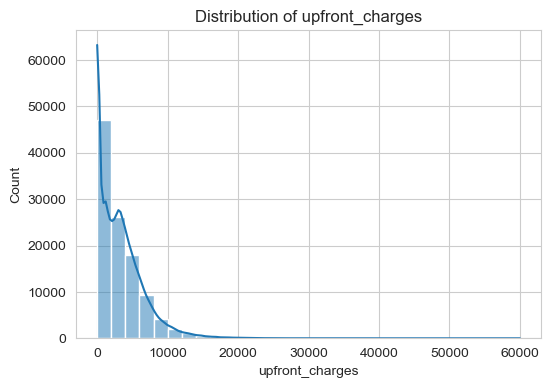

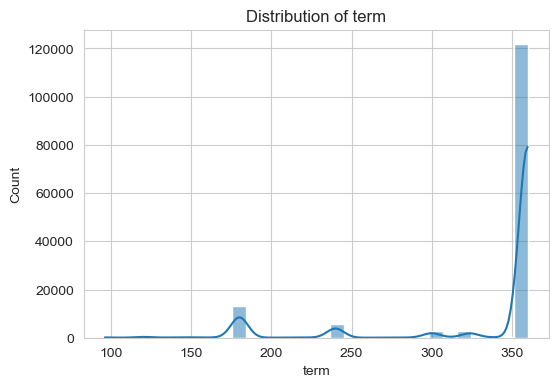

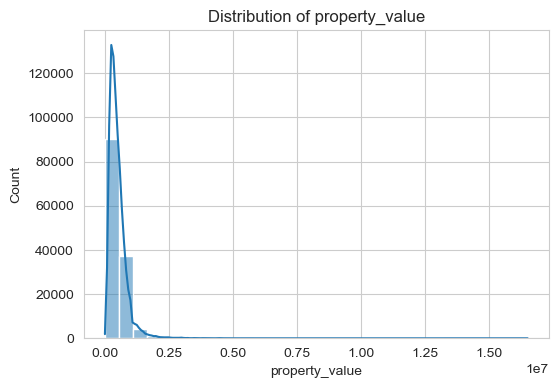

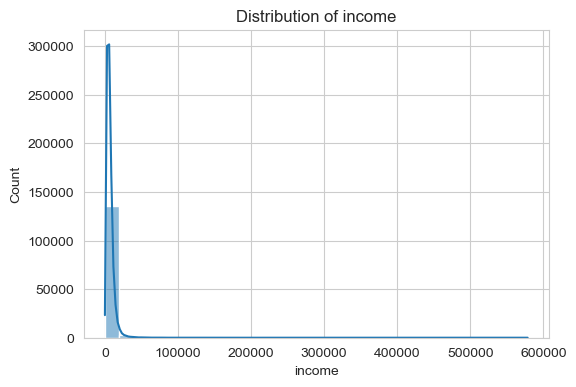

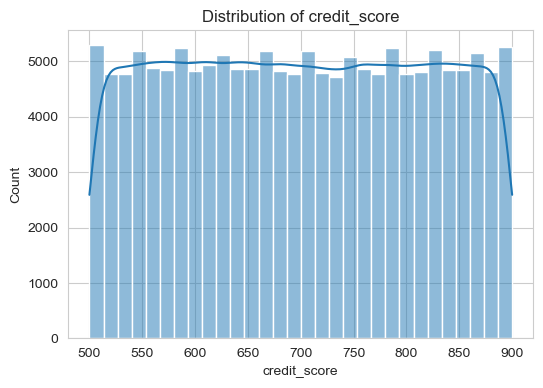

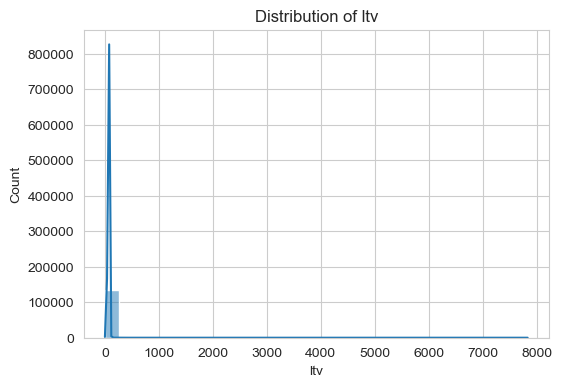

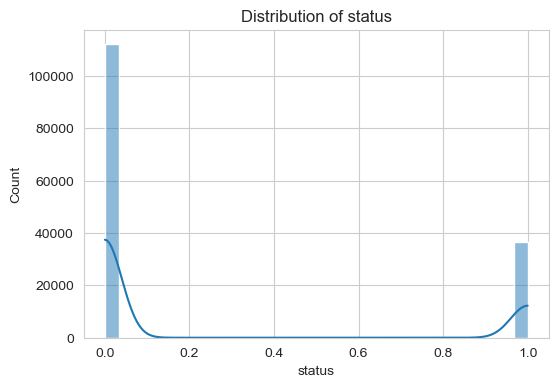

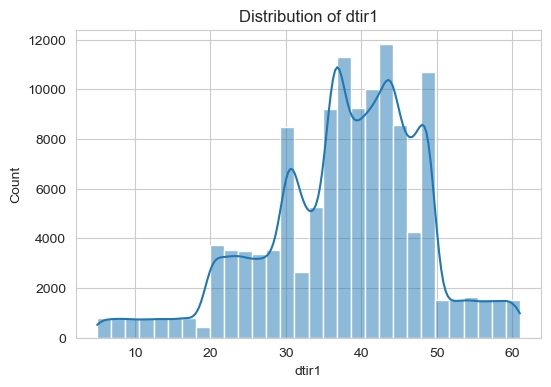

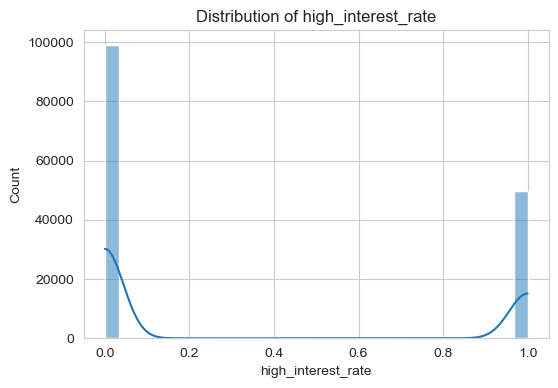

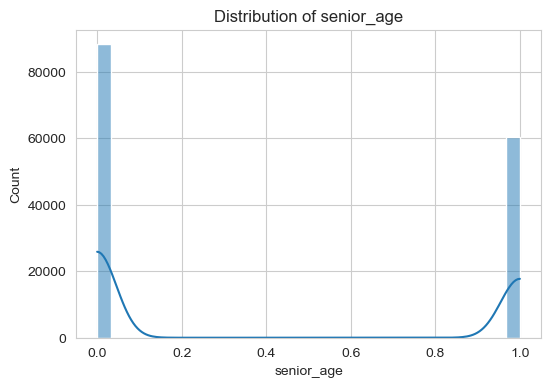

In [14]:
# Univariate analysis for numerical columns
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.show()

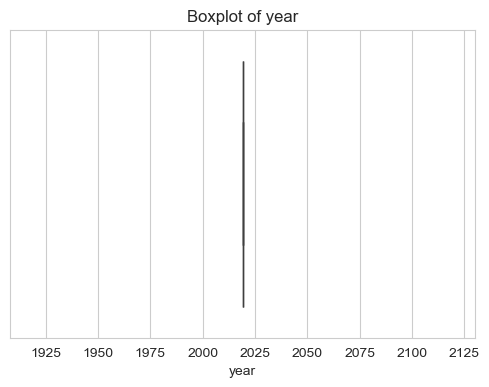

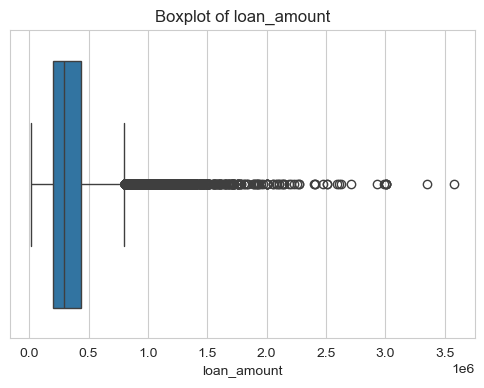

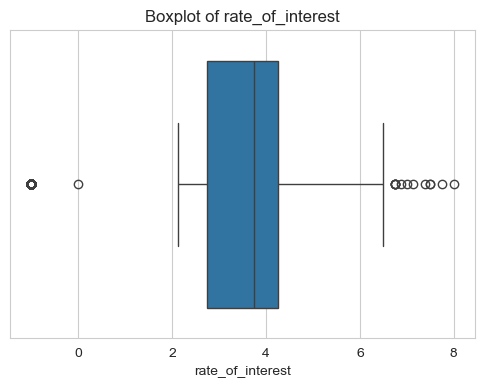

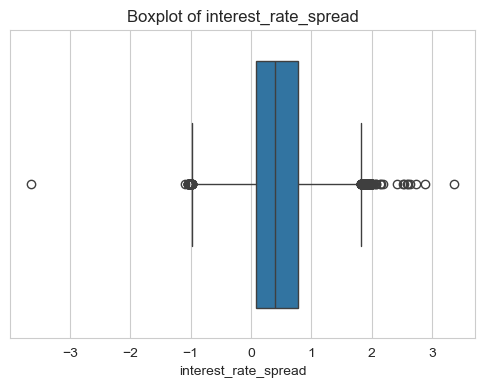

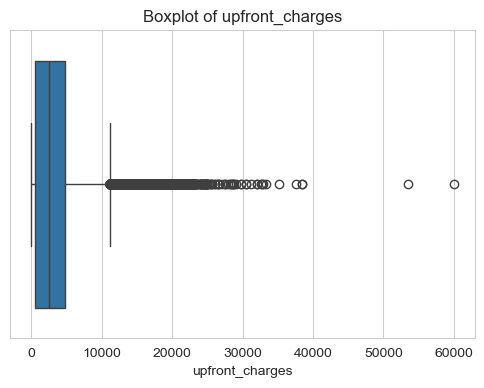

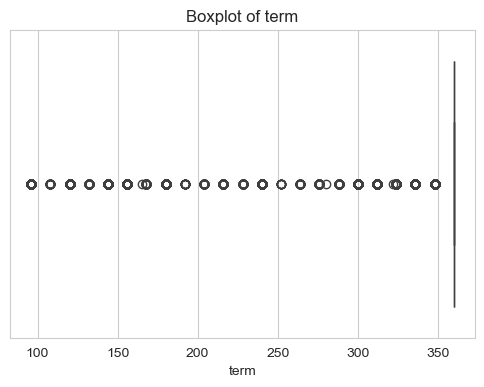

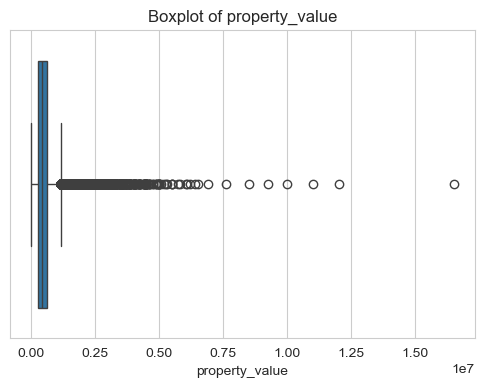

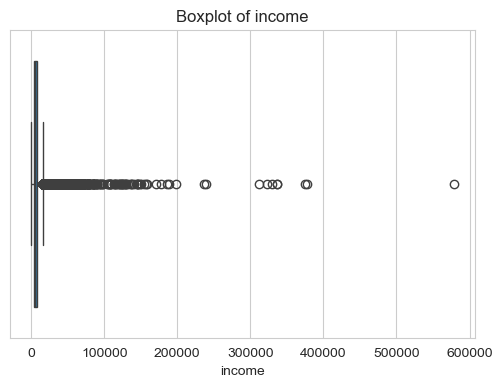

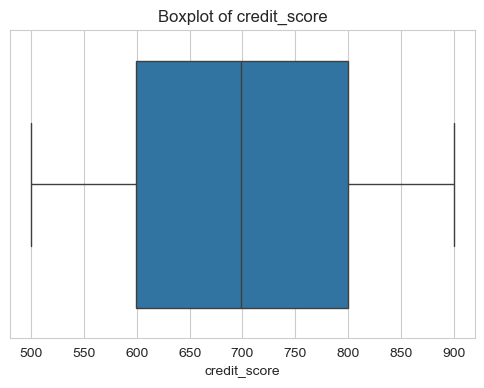

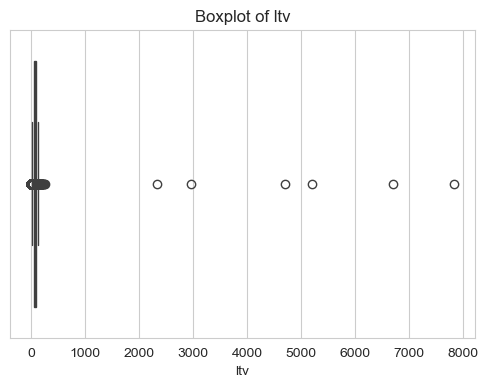

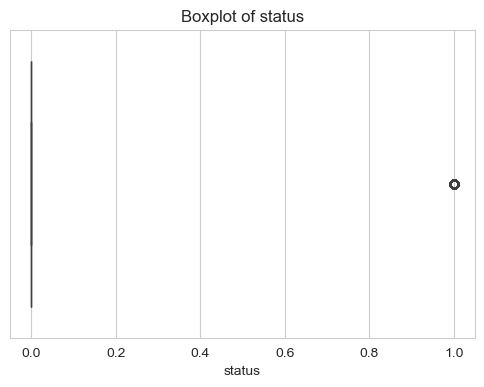

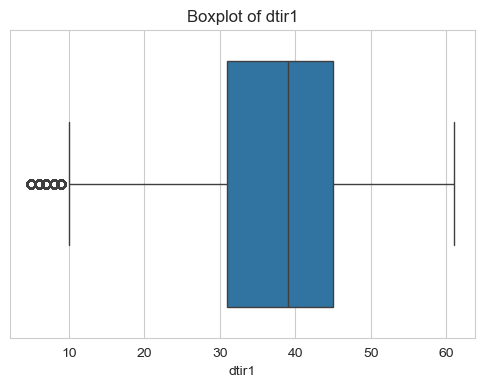

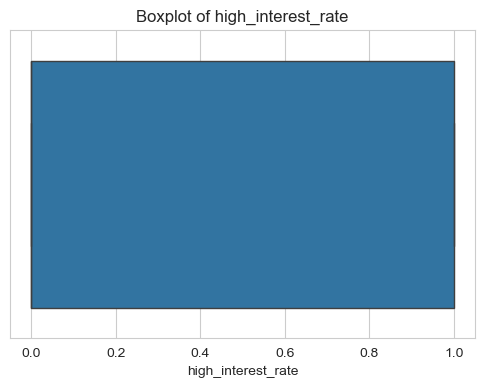

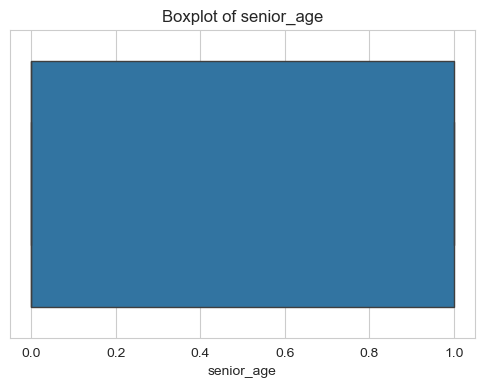

In [15]:
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [16]:
# Skewness of numerical columns
skew_df = pd.DataFrame({
    "Column": num_cols,
    "Skewness": [df[col].skew() for col in num_cols]
}).sort_values(by="Skewness", ascending=False)

skew_df

,Column,Skewness
9,ltv,120.615337
7,income,17.307695
6,property_value,4.586276
4,upfront_charges,1.754076
1,loan_amount,1.666998
10,status,1.176762
12,high_interest_rate,0.705434
13,senior_age,0.380191
3,interest_rate_spread,0.280762
8,credit_score,0.004767


In [17]:
def skew_type(x):
    if x > 1:
        return "Highly Right Skewed"
    elif x > 0.5:
        return "Moderately Right Skewed"
    elif x < -1:
        return "Highly Left Skewed"
    elif x < -0.5:
        return "Moderately Left Skewed"
    else:
        return "Approximately Symmetric"

skew_df["Interpretation"] = skew_df["Skewness"].apply(skew_type)
skew_df

,Column,Skewness,Interpretation
9,ltv,120.615337,Highly Right Skewed
7,income,17.307695,Highly Right Skewed
6,property_value,4.586276,Highly Right Skewed
4,upfront_charges,1.754076,Highly Right Skewed
1,loan_amount,1.666998,Highly Right Skewed
10,status,1.176762,Highly Right Skewed
12,high_interest_rate,0.705434,Moderately Right Skewed
13,senior_age,0.380191,Approximately Symmetric
3,interest_rate_spread,0.280762,Approximately Symmetric
8,credit_score,0.004767,Approximately Symmetric


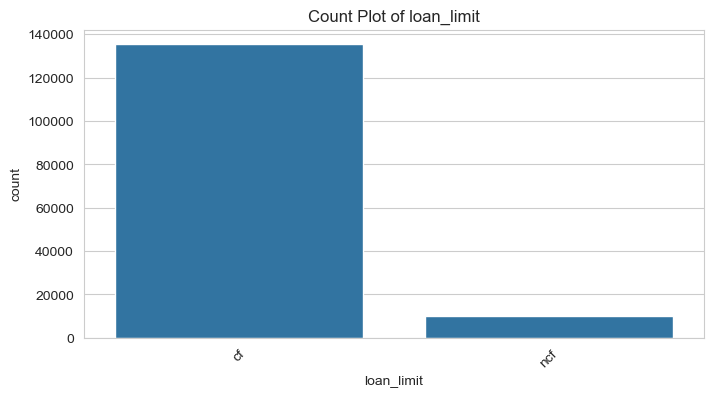

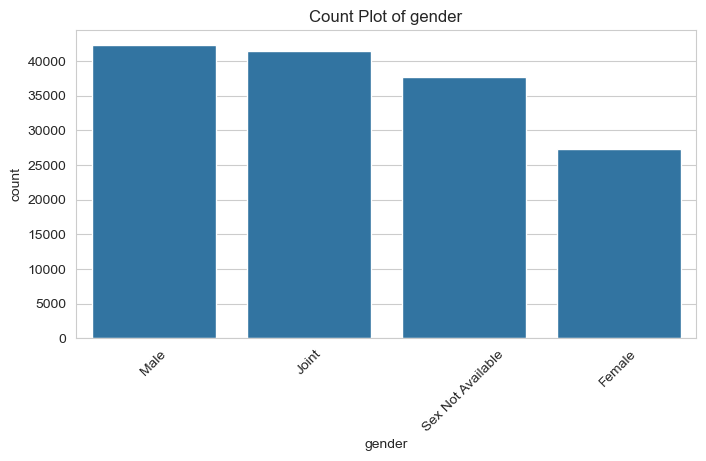

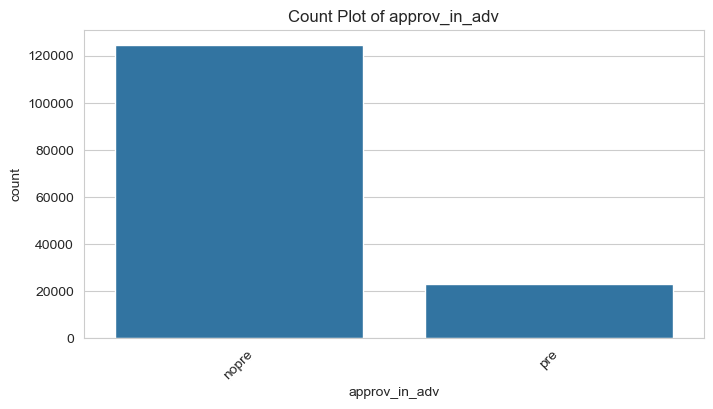

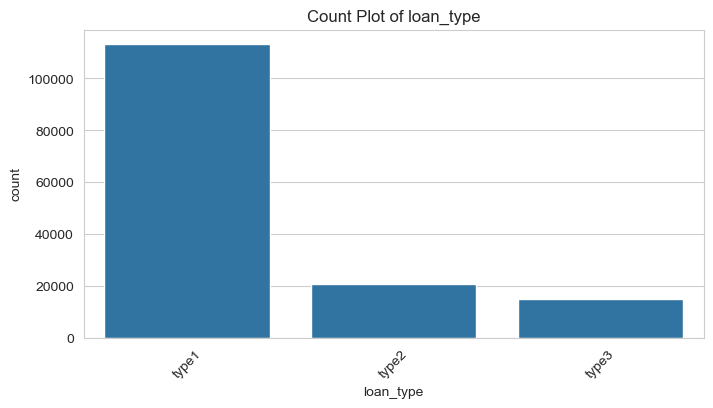

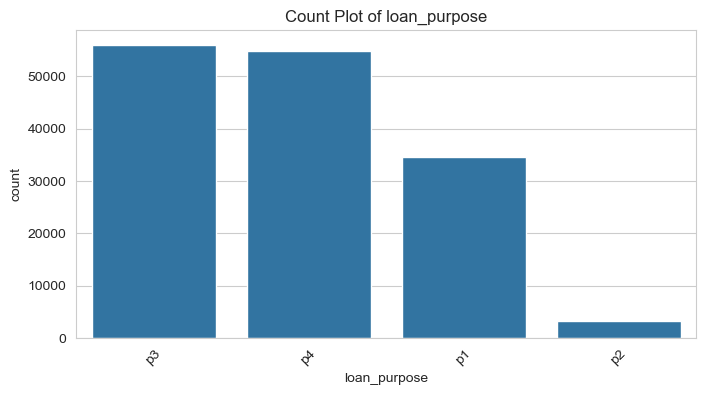

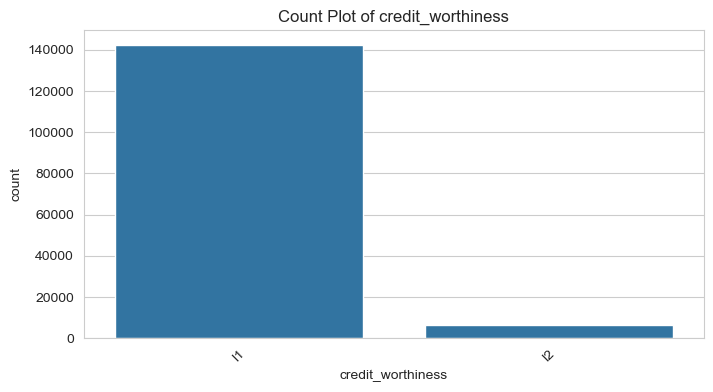

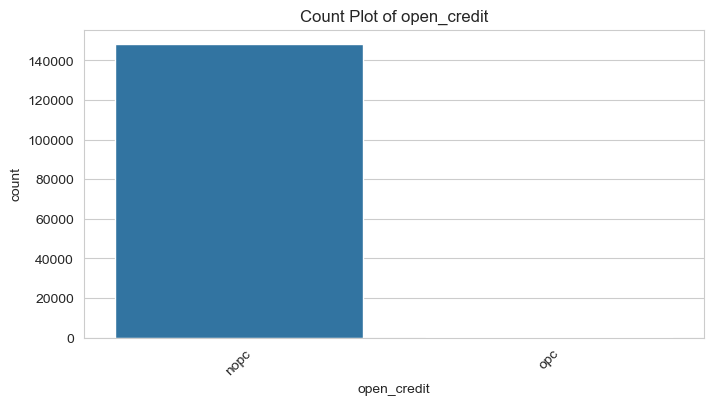

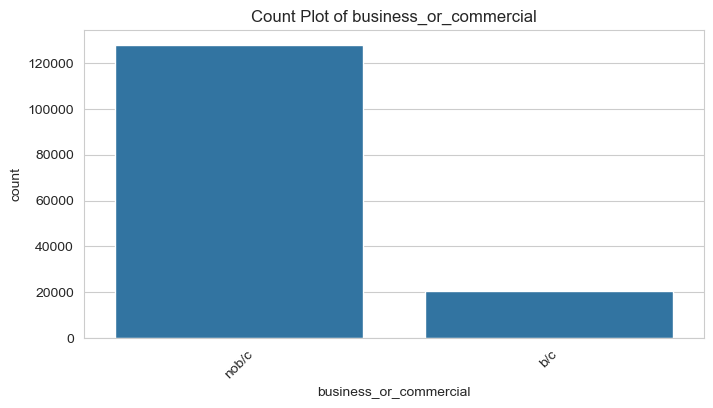

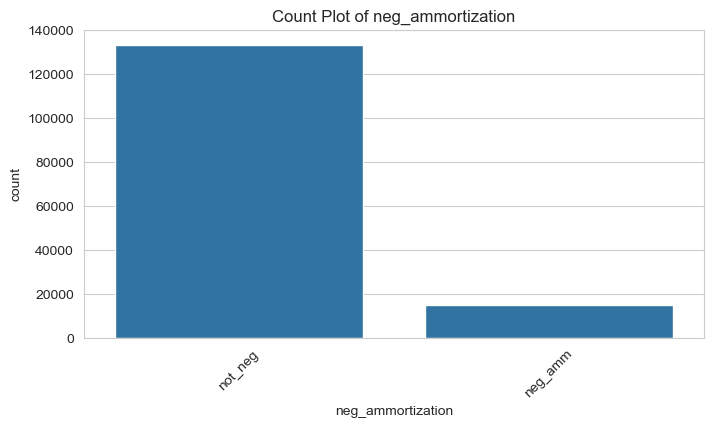

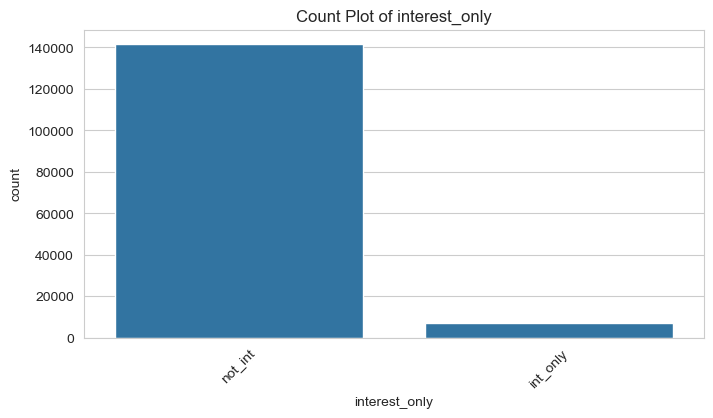

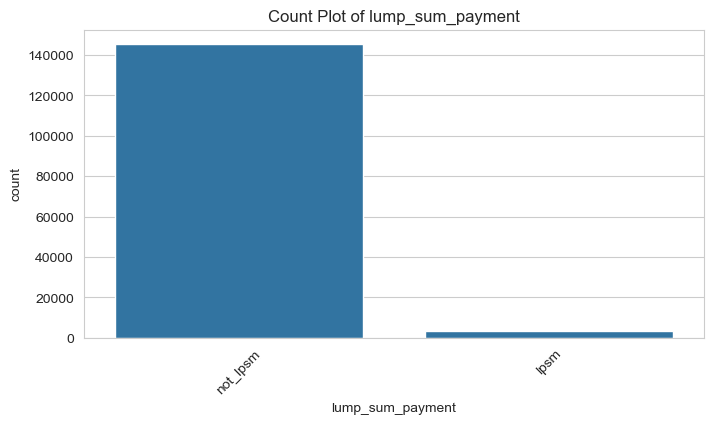

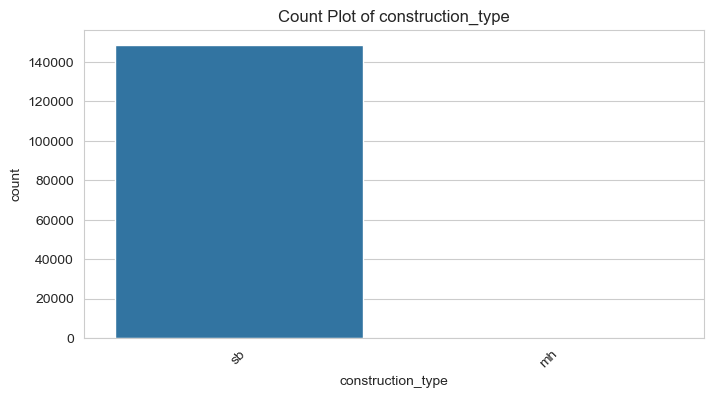

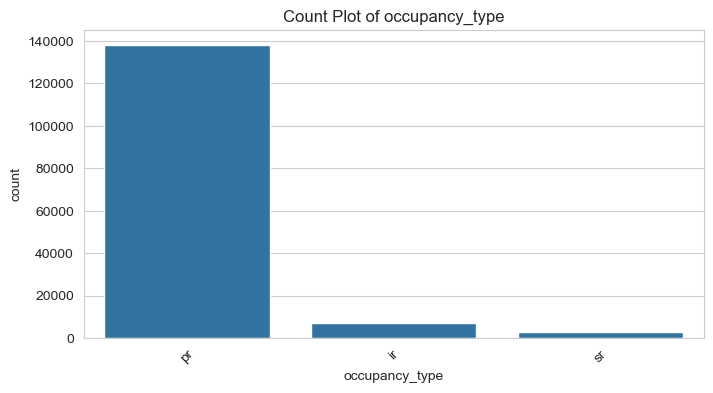

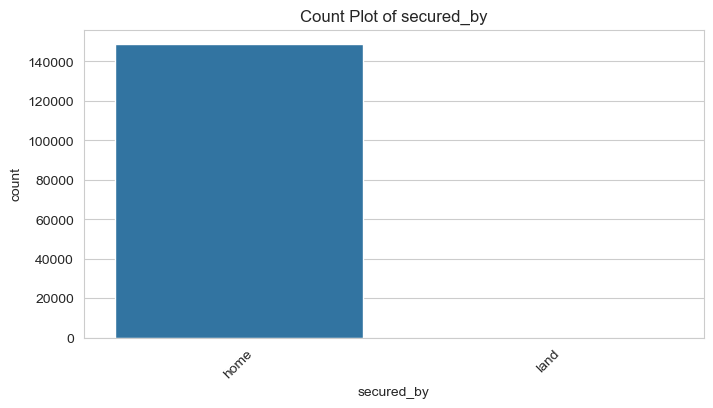

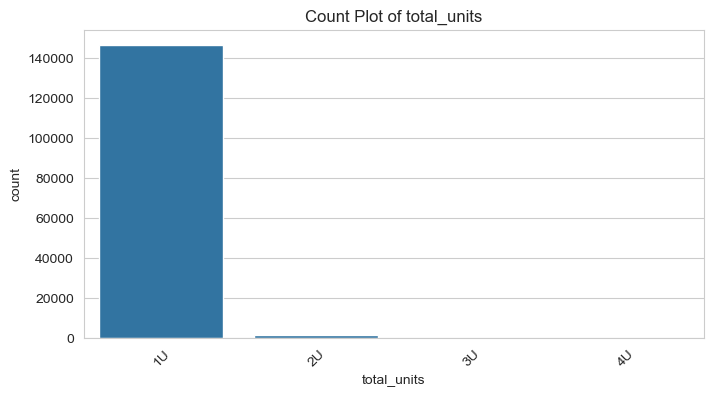

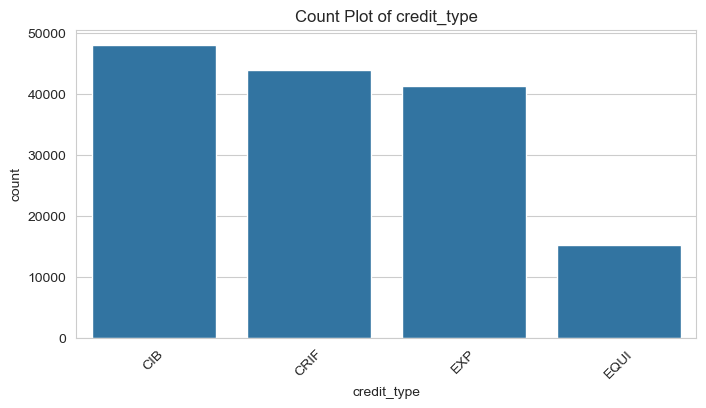

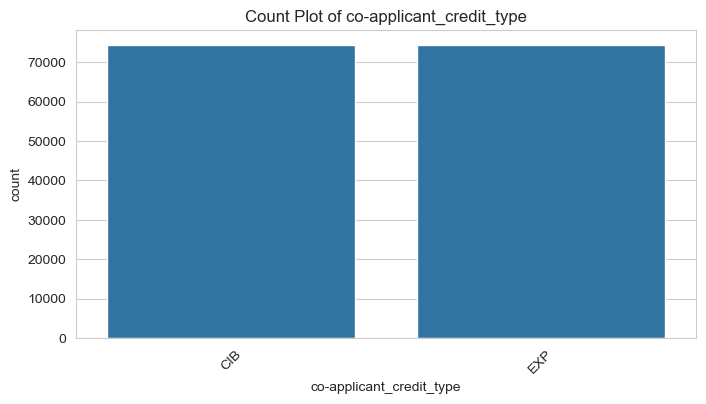

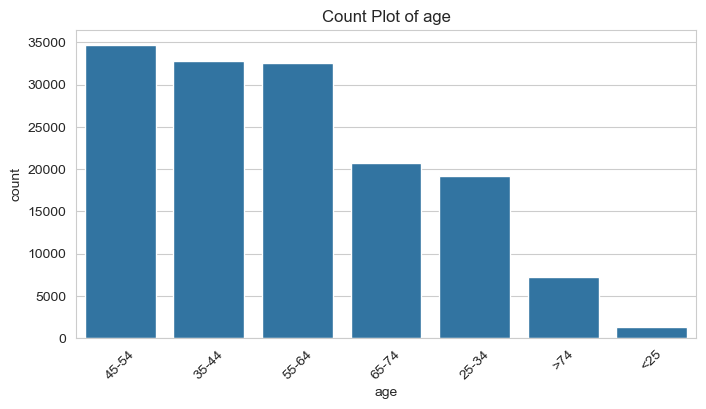

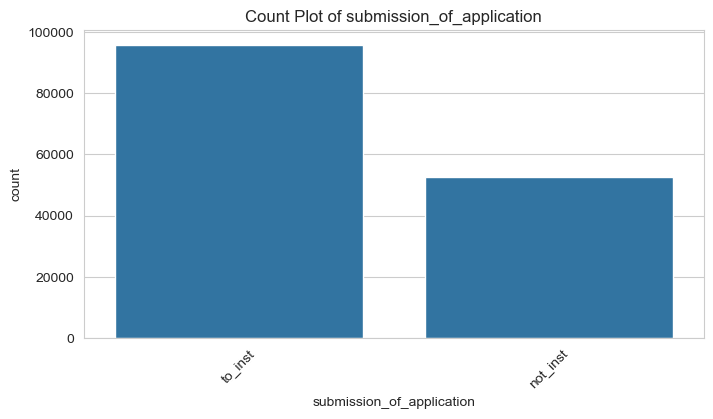

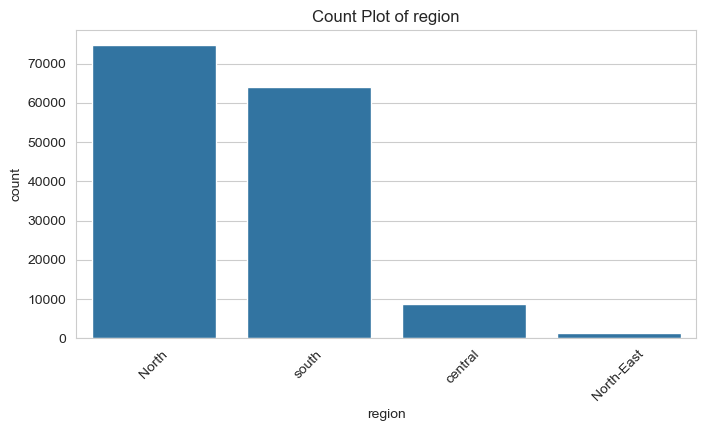

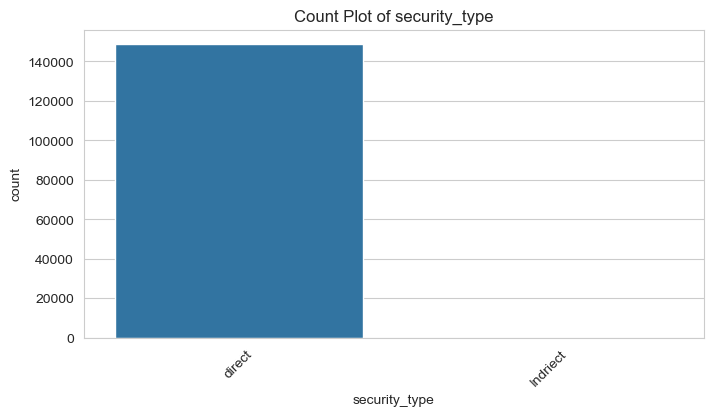

In [18]:
#Categorical feature analysis
for col in cat_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(x=col, data=df, order=df[col].value_counts().index)
    plt.title(f"Count Plot of {col}")
    plt.xticks(rotation=45)
    plt.show()

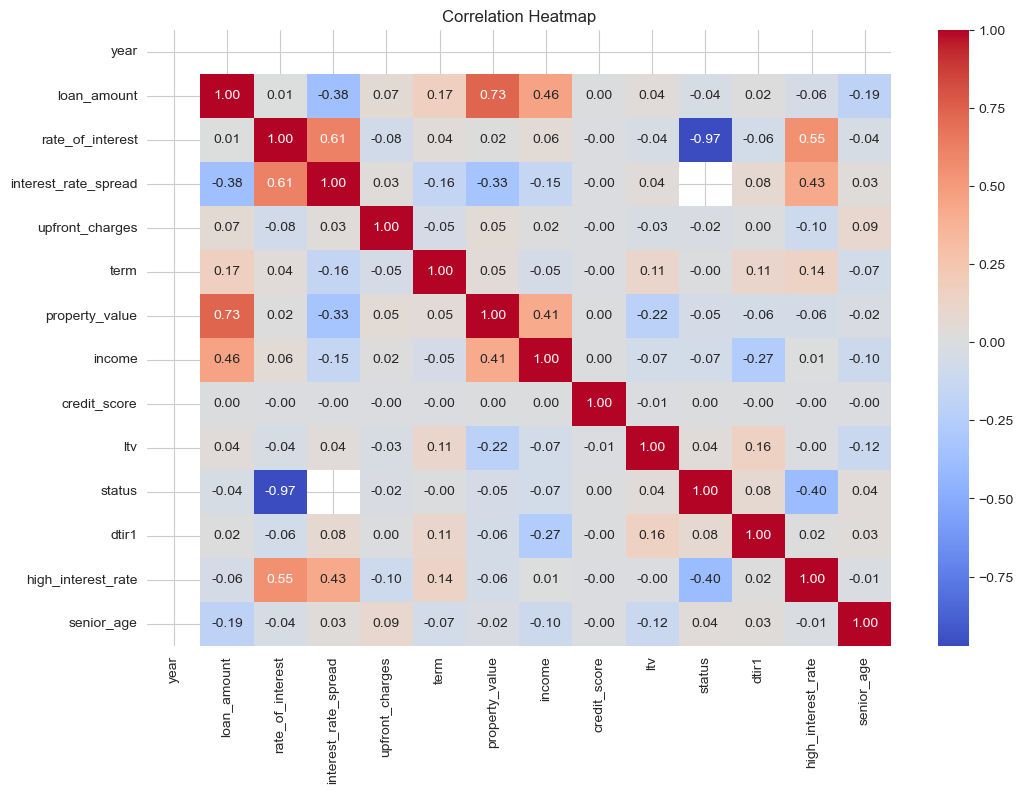

In [19]:
plt.figure(figsize=(12,8))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [20]:
target_corr = df[num_cols].corr()["status"].sort_values(ascending=False)
print(target_corr)

status                  1.000000
dtir1                   0.078083
senior_age              0.039645
ltv                     0.038895
credit_score            0.004004
term                   -0.000240
upfront_charges        -0.019138
loan_amount            -0.036825
property_value         -0.048864
income                 -0.065119
high_interest_rate     -0.400395
rate_of_interest       -0.971701
year                         NaN
interest_rate_spread         NaN
Name: status, dtype: float64


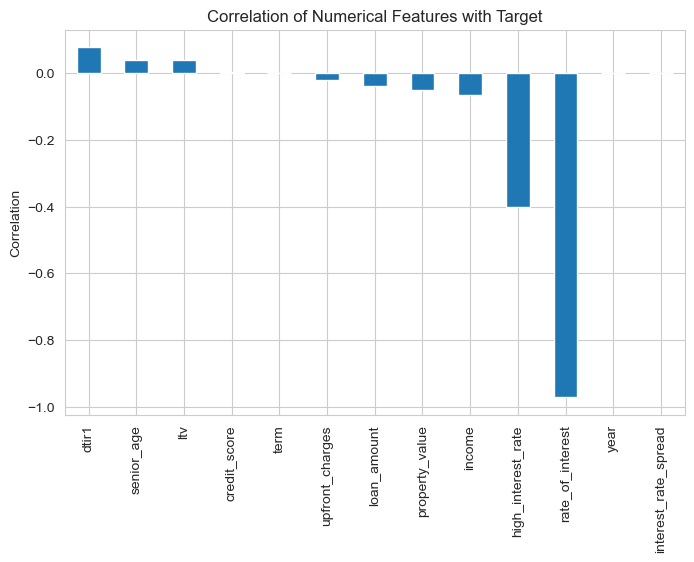

In [21]:
plt.figure(figsize=(8,5))
target_corr.drop("status").plot(kind="bar")
plt.title("Correlation of Numerical Features with Target")
plt.ylabel("Correlation")
plt.show()

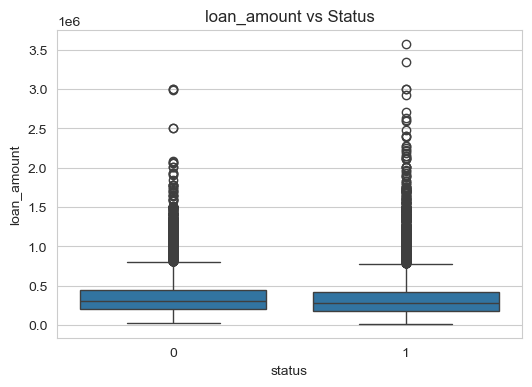

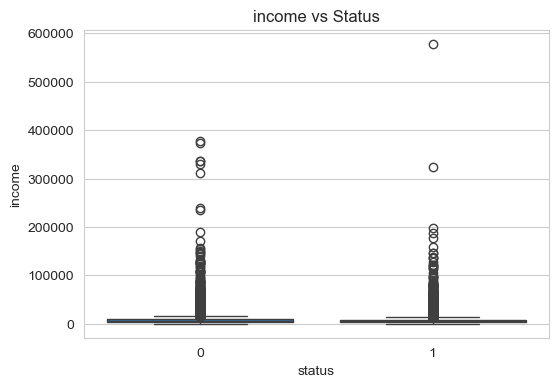

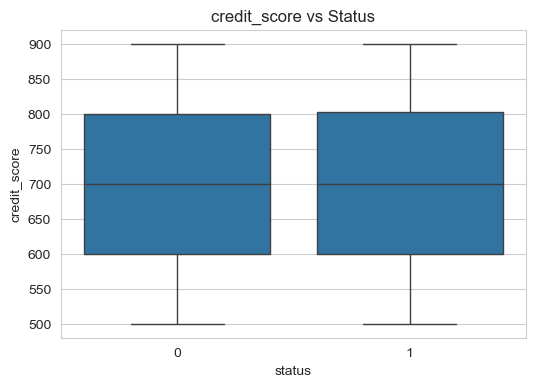

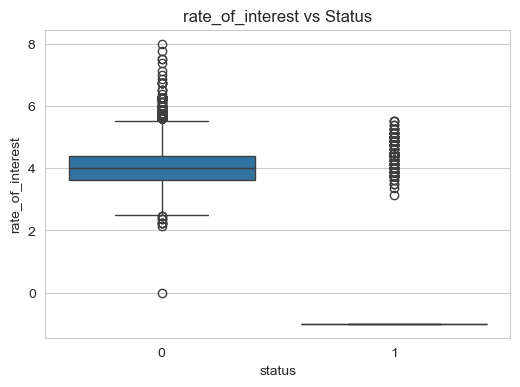

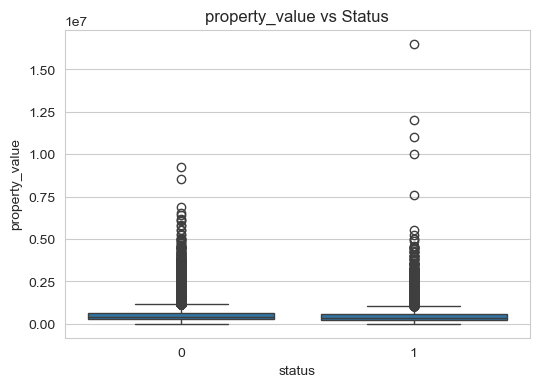

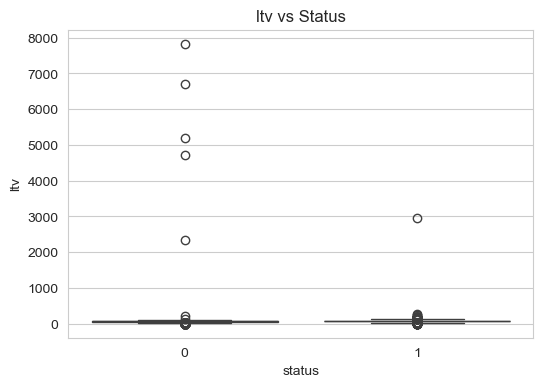

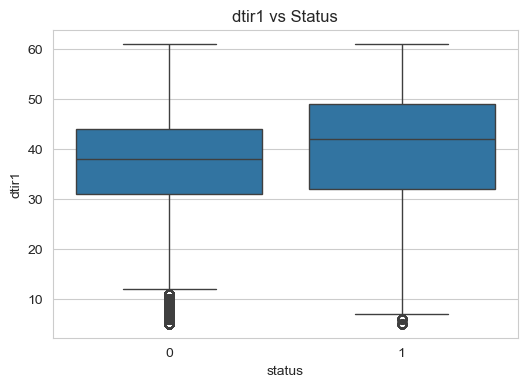

In [22]:
#Numerical features vs target
important_num = ["loan_amount", "income", "credit_score", "rate_of_interest", "property_value", "ltv", "dtir1"]

for col in important_num:
    if col in df.columns:
        plt.figure(figsize=(6,4))
        sns.boxplot(x="status", y=col, data=df)
        plt.title(f"{col} vs Status")
        plt.show()

In [23]:
# Mean / median by target
for col in important_num:
    if col in df.columns:
        print(f"\n{col} grouped by status")
        print(df.groupby("status")[col].agg(["mean", "median", "min", "max"]))


loan_amount grouped by status
                 mean    median    min      max
status                                         
0       334990.774875  306500.0  26500  3006500
1       319275.184912  276500.0  16500  3576500

income grouped by status
               mean  median  min       max
status                                    
0       7204.014214  6000.0  0.0  377220.0
1       6231.806780  4860.0  0.0  578580.0

credit_score grouped by status
              mean  median  min  max
status                              
0       699.523793   699.0  500  900
1       700.600344   700.0  500  900

rate_of_interest grouped by status
            mean  median  min  max
status                            
0       4.044931    3.99  0.0  8.0
1      -0.970793   -1.00 -1.0  5.5

property_value grouped by status
                 mean    median     min         max
status                                             
0       505606.066286  428000.0  8000.0   9268000.0
1       457786.009377  348000.0  

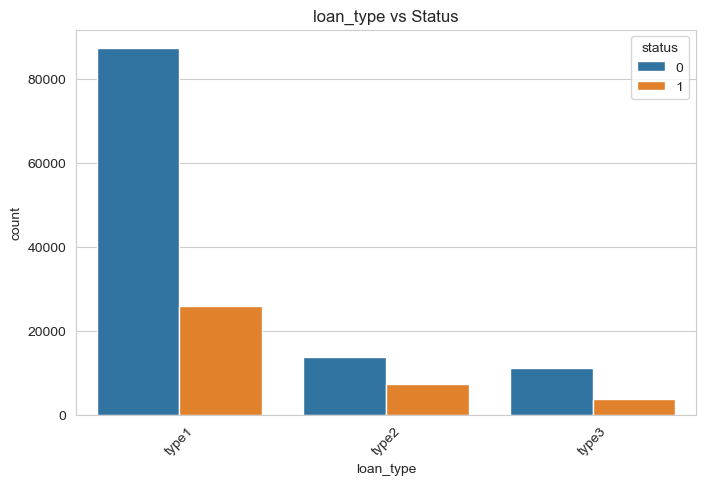

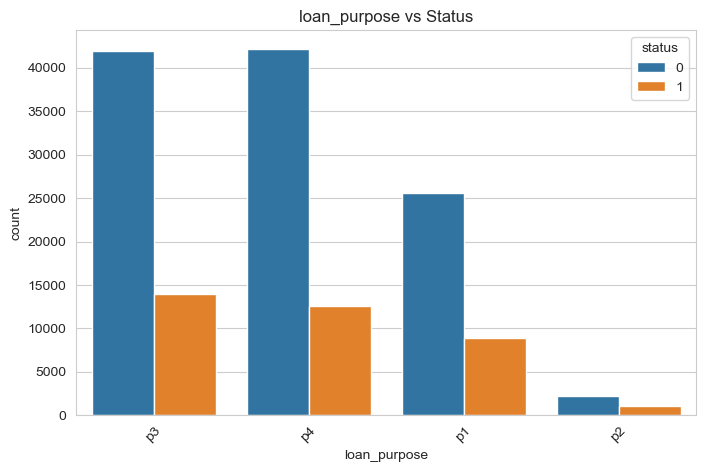

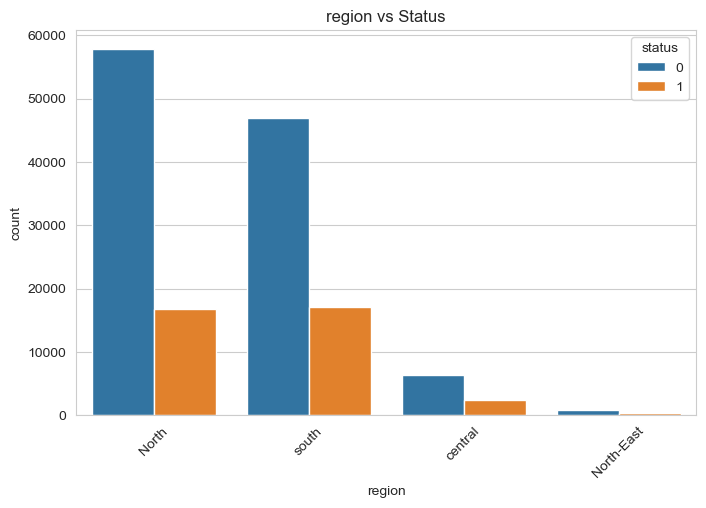

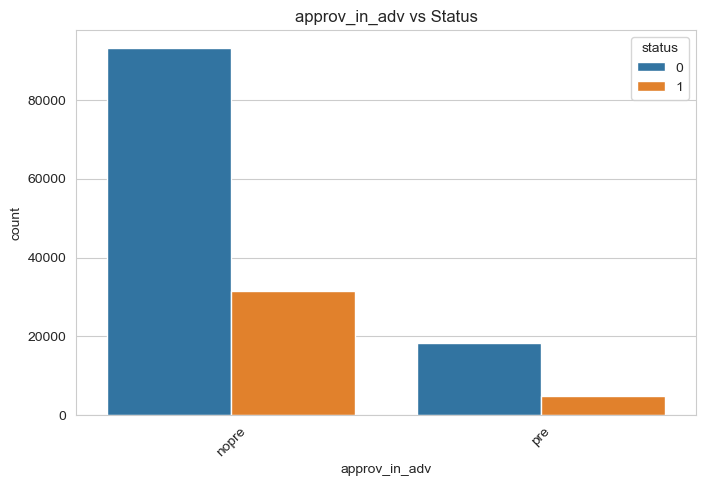

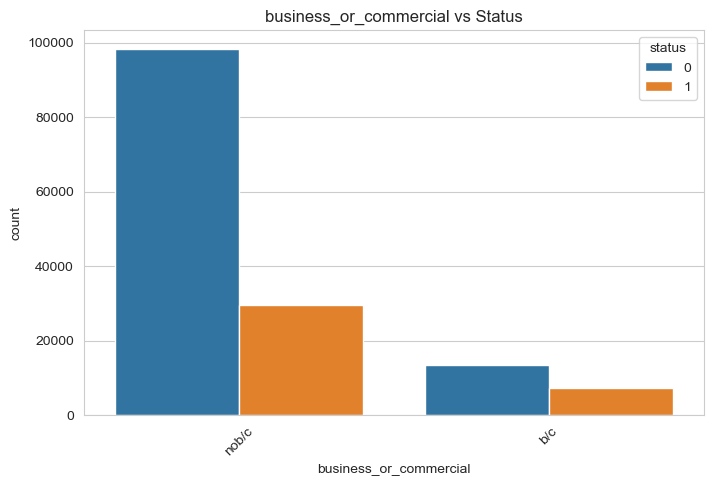

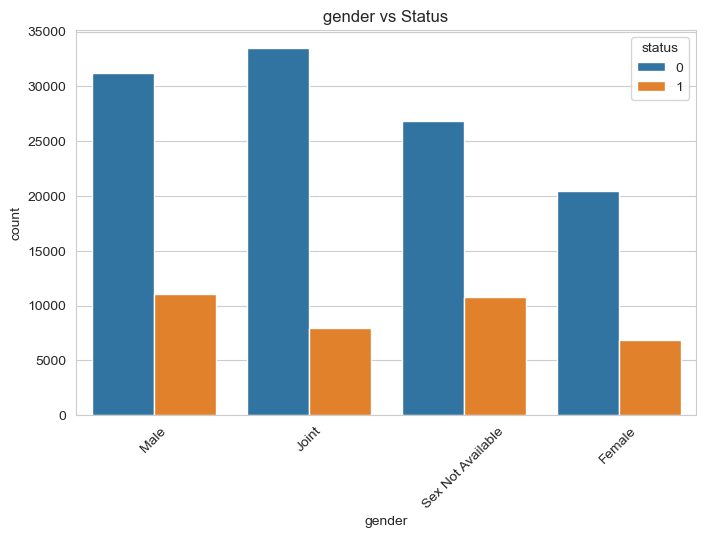

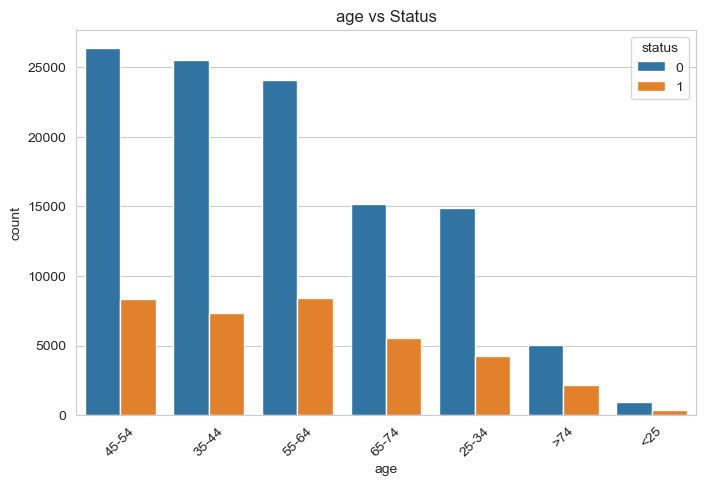

In [24]:
#Categorical features vs target
important_cat = ["loan_type", "loan_purpose", "region", "approv_in_adv",
                 "business_or_commercial", "gender", "age"]

for col in important_cat:
    if col in df.columns:
        plt.figure(figsize=(8,5))
        sns.countplot(x=col, hue="status", data=df, order=df[col].value_counts().index)
        plt.title(f"{col} vs Status")
        plt.xticks(rotation=45)
        plt.show()

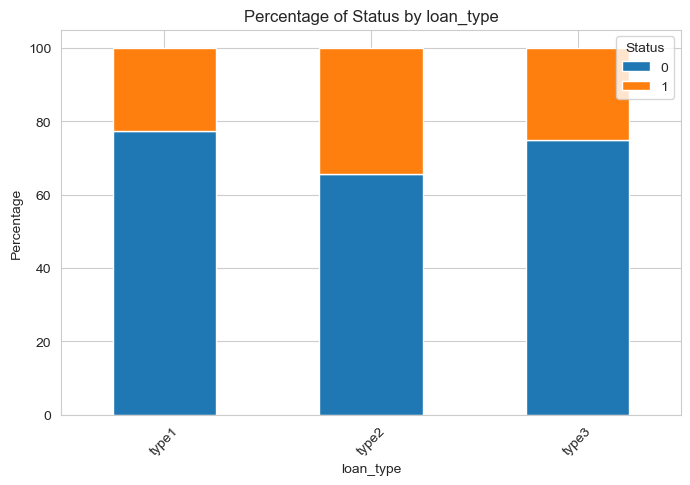

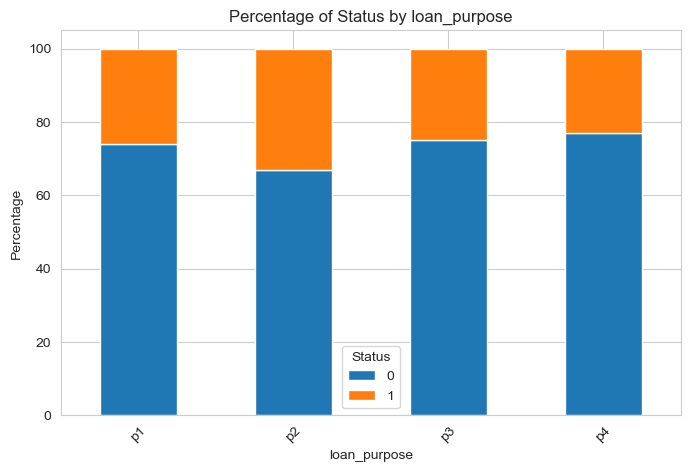

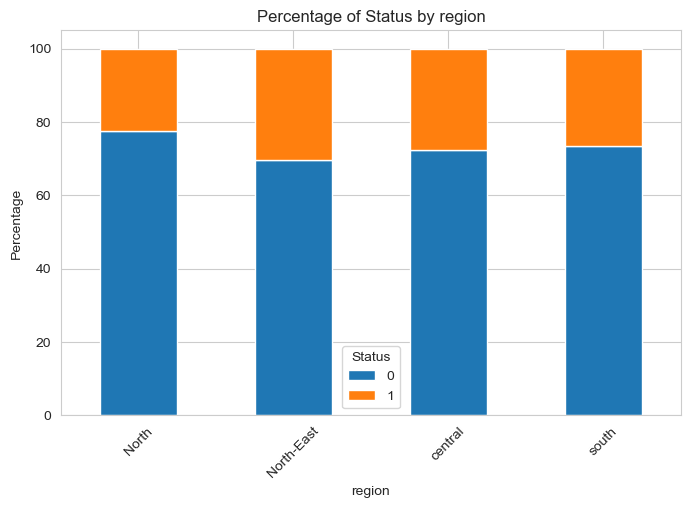

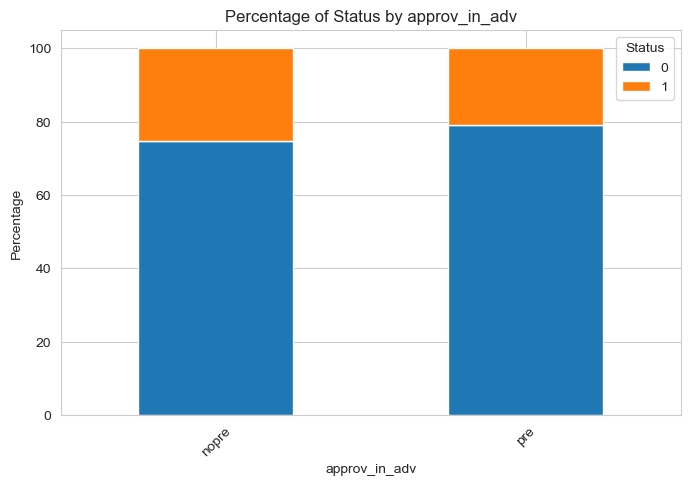

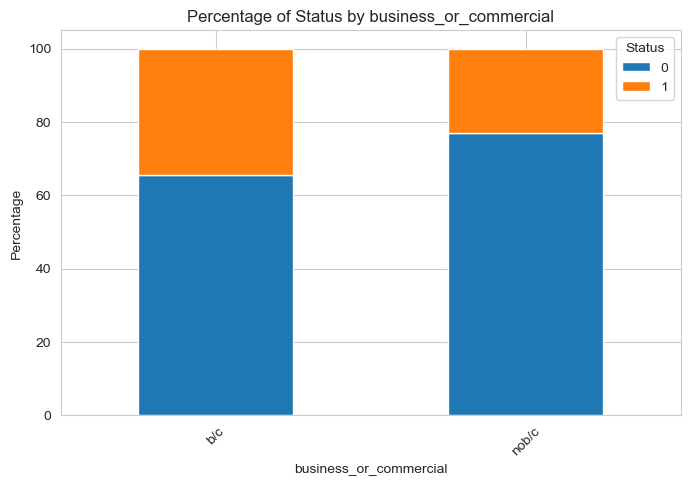

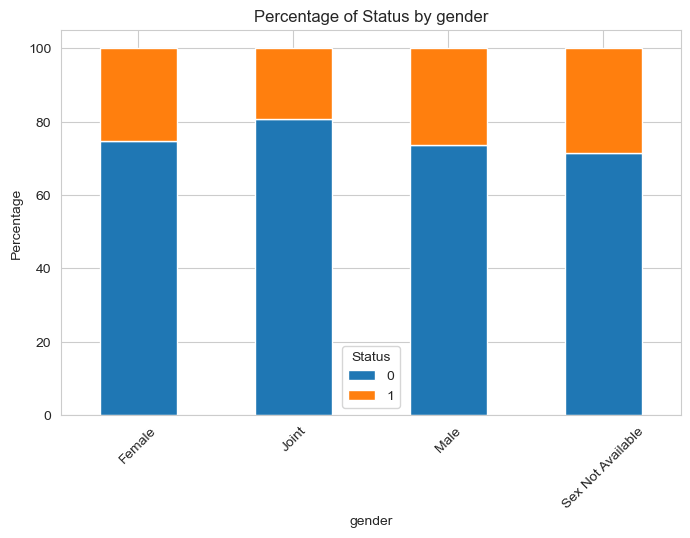

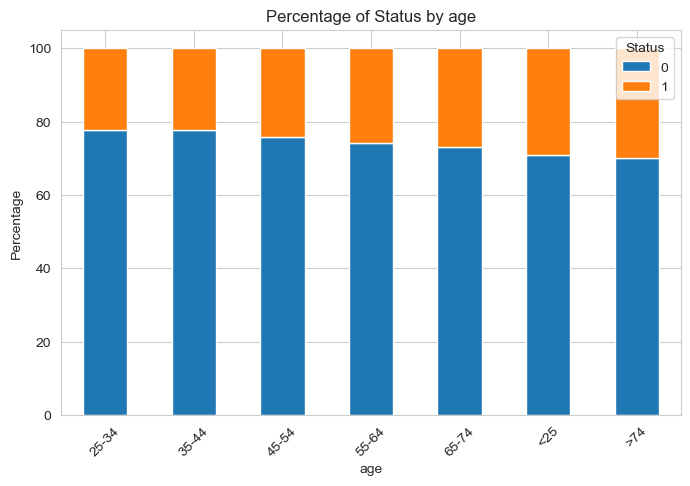

In [25]:
#Stacked percentage plot for categorical columns vs target
for col in important_cat:
    if col in df.columns:
        temp = pd.crosstab(df[col], df["status"], normalize="index") * 100
        temp.plot(kind="bar", stacked=True, figsize=(8,5))
        plt.title(f"Percentage of Status by {col}")
        plt.ylabel("Percentage")
        plt.xticks(rotation=45)
        plt.legend(title="Status")
        plt.show()

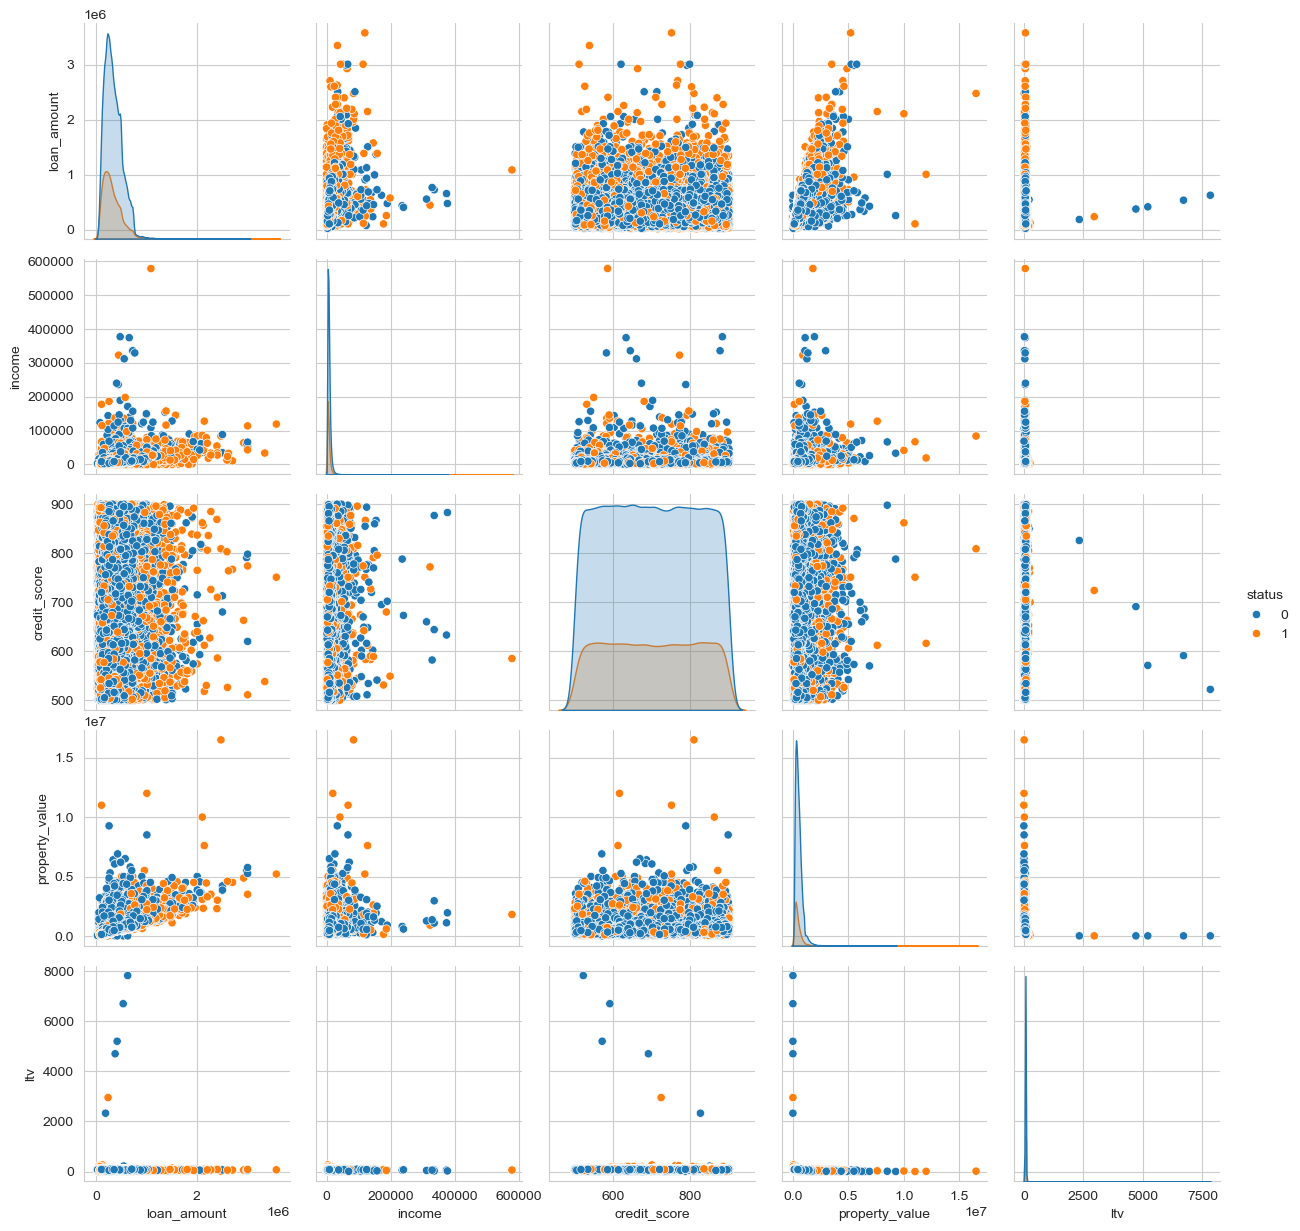

In [27]:
#Pairplot for selected important numerical columns
pair_cols = [col for col in ["loan_amount", "income", "credit_score", "property_value", "ltv", "status"] if col in df.columns]

sns.pairplot(df[pair_cols], hue="status")
plt.show()

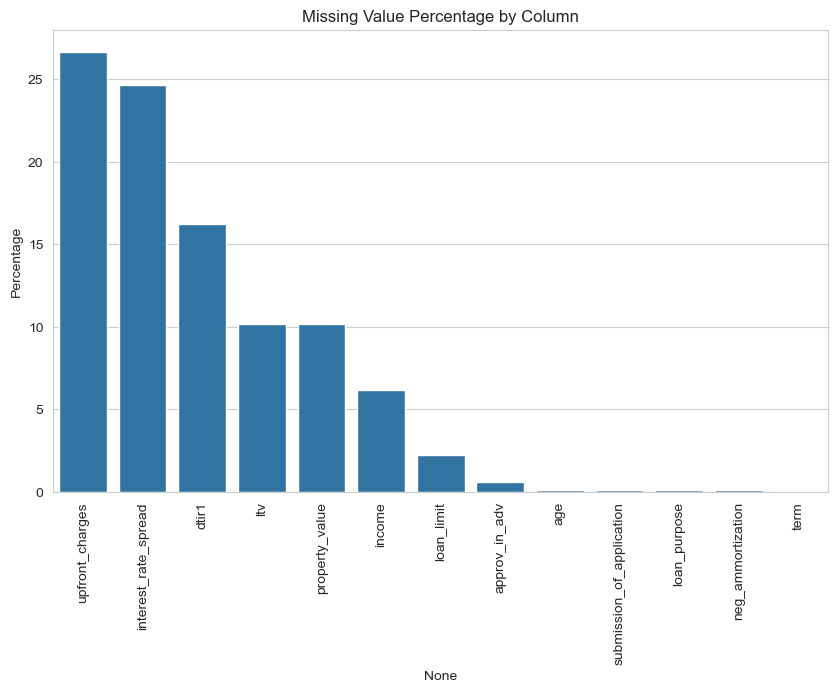

In [28]:
#Best 6 plots to keep for your report/poster
# 1. Missing values percentage
missing_plot = missing_df[missing_df["Missing Values"] > 0]
plt.figure(figsize=(10,6))
sns.barplot(x=missing_plot.index, y=missing_plot["Percentage"])
plt.xticks(rotation=90)
plt.title("Missing Value Percentage by Column")
plt.show()

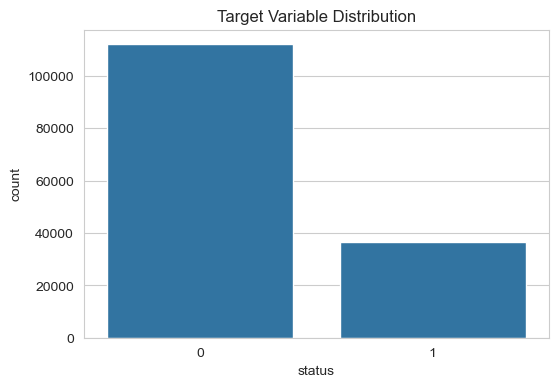

In [29]:
# 2. Target distribution
plt.figure(figsize=(6,4))
sns.countplot(x="status", data=df)
plt.title("Target Variable Distribution")
plt.show()

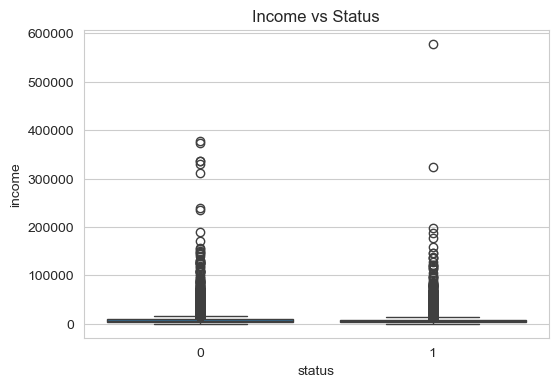

In [30]:
# 3. Income vs status
if "income" in df.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x="status", y="income", data=df)
    plt.title("Income vs Status")
    plt.show()

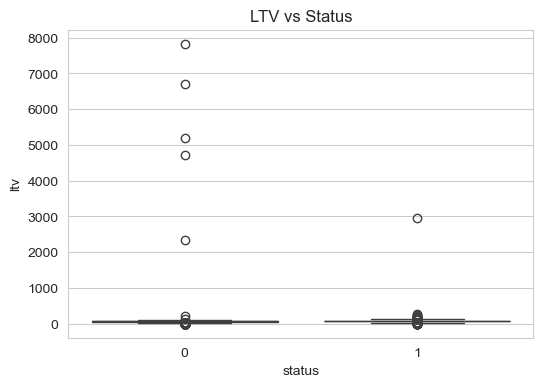

In [31]:
# 4. LTV vs status
if "ltv" in df.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x="status", y="ltv", data=df)
    plt.title("LTV vs Status")
    plt.show()

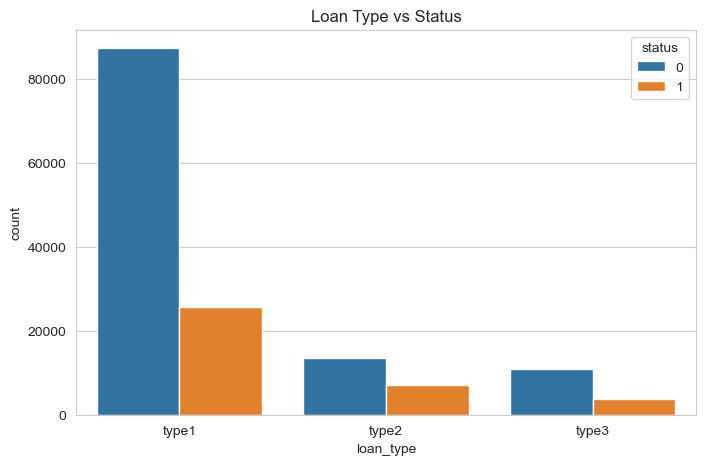

In [32]:
# 5. Loan type vs status
if "loan_type" in df.columns:
    plt.figure(figsize=(8,5))
    sns.countplot(x="loan_type", hue="status", data=df)
    plt.title("Loan Type vs Status")
    plt.show()

In [26]:
# 6. Correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

ValueError: could not convert string to float: '35-44'

<Figure size 1200x800 with 0 Axes>

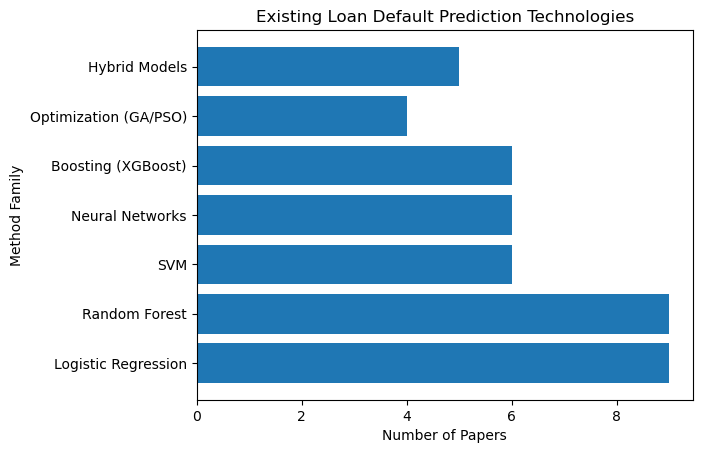

In [1]:
import matplotlib.pyplot as plt

methods = [
    "Logistic Regression",
    "Random Forest",
    "SVM",
    "Neural Networks",
    "Boosting (XGBoost)",
    "Optimization (GA/PSO)",
    "Hybrid Models"
]

values = [9, 9, 6, 6, 6, 4, 5]

plt.barh(methods, values)
plt.xlabel("Number of Papers")
plt.ylabel("Method Family")
plt.title("Existing Loan Default Prediction Technologies")
plt.show()

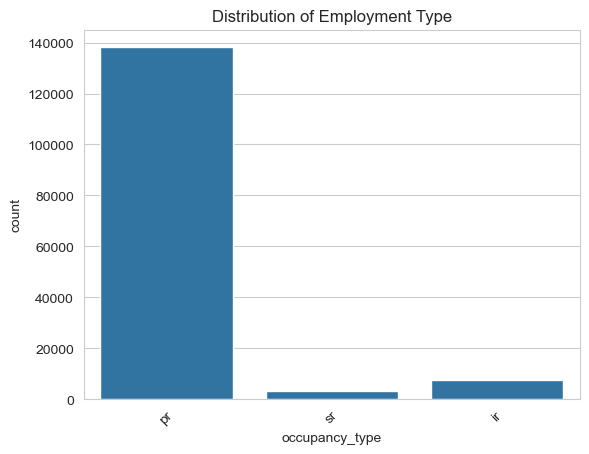

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='occupancy_type', data=df)
plt.title("Distribution of Occupany Type")
plt.xticks(rotation=45)
plt.show()

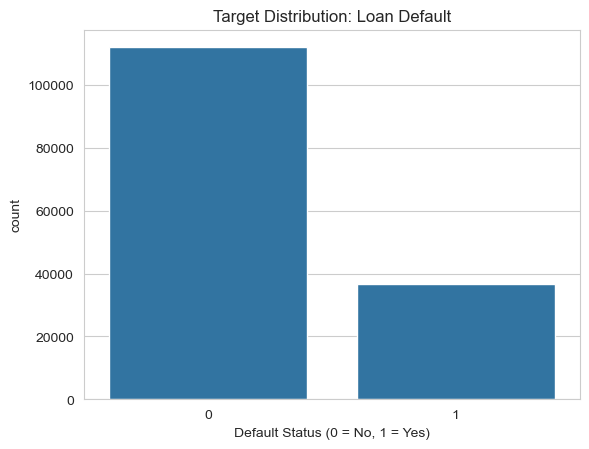

In [11]:
sns.countplot(x='status', data=df)
plt.title("Target Distribution: Loan Default")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.show()

In [14]:
print(df.columns)

Index(['Unnamed: 0', 'id', 'year', 'loan_limit', 'gender', 'approv_in_adv',
       'loan_type', 'loan_purpose', 'credit_worthiness', 'open_credit',
       'business_or_commercial', 'loan_amount', 'rate_of_interest',
       'interest_rate_spread', 'upfront_charges', 'term', 'neg_ammortization',
       'interest_only', 'lump_sum_payment', 'property_value',
       'construction_type', 'occupancy_type', 'secured_by', 'total_units',
       'income', 'credit_type', 'credit_score', 'co-applicant_credit_type',
       'age', 'submission_of_application', 'ltv', 'region', 'security_type',
       'status', 'dtir1', 'high_interest_rate', 'senior_age'],
      dtype='object')


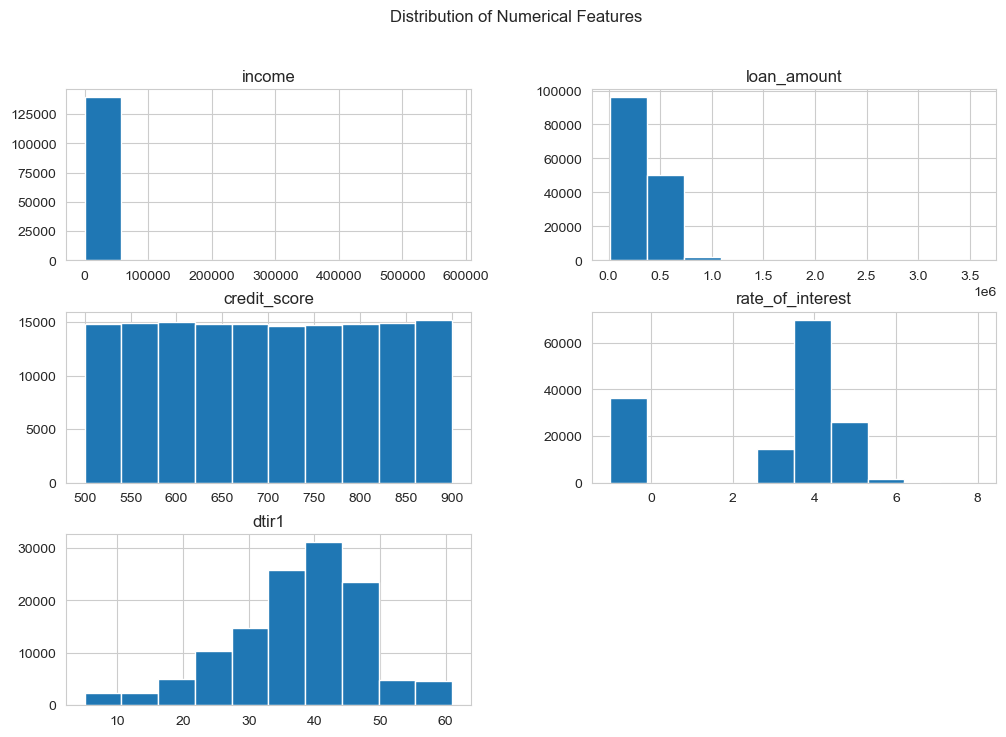

In [15]:
import matplotlib.pyplot as plt

num_cols = ['age','income','loan_amount','credit_score','rate_of_interest','dtir1']

df[num_cols].hist(figsize=(12,8))
plt.suptitle("Distribution of Numerical Features")
plt.show()

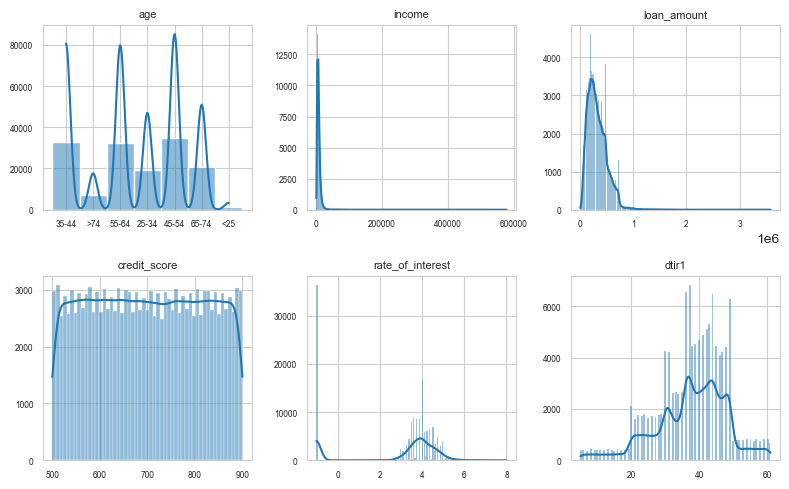

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ['age', 'income', 'loan_amount', 'credit_score', 'rate_of_interest', 'dtir1']

plt.figure(figsize=(8, 5))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(col, fontsize=8)
    plt.xlabel("")
    plt.ylabel("")
    plt.xticks(fontsize=6)
    plt.yticks(fontsize=6)

plt.tight_layout()
plt.show()

C:\Users\harsh\AppData\Local\Temp\ipykernel_27196\4232963781.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='status', data=df, palette=['#66c2a5', '#fc8d62'], width=0.5)


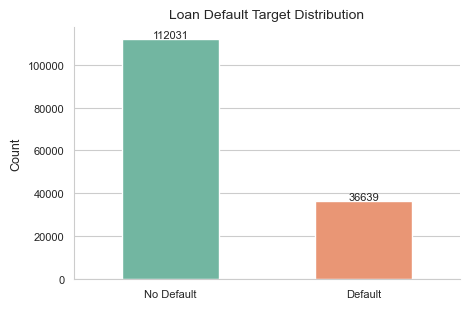

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(4.8, 3.2))
ax = sns.countplot(x='status', data=df, palette=['#66c2a5', '#fc8d62'], width=0.5)

plt.title("Loan Default Target Distribution", fontsize=10)
plt.xlabel("")
plt.ylabel("Count", fontsize=9)
plt.xticks([0, 1], ['No Default', 'Default'], fontsize=8)
plt.yticks(fontsize=8)
sns.despine()

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2, p.get_height() + 200),
                ha='center', fontsize=8)

plt.tight_layout()
plt.show()

C:\Users\harsh\AppData\Local\Temp\ipykernel_27196\201894714.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='status', data=df, palette='Set2')


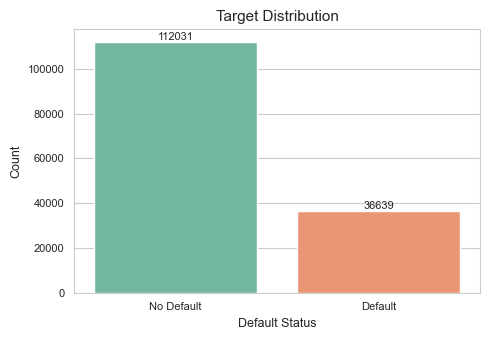

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5, 3.5))
ax = sns.countplot(x='status', data=df, palette='Set2')

plt.title("Target Distribution", fontsize=11)
plt.xlabel("Default Status", fontsize=9)
plt.ylabel("Count", fontsize=9)
plt.xticks([0, 1], ['No Default', 'Default'], fontsize=8)
plt.yticks(fontsize=8)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

C:\Users\harsh\AppData\Local\Temp\ipykernel_27196\3191721848.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='loan_purpose', data=df, palette='Set2')


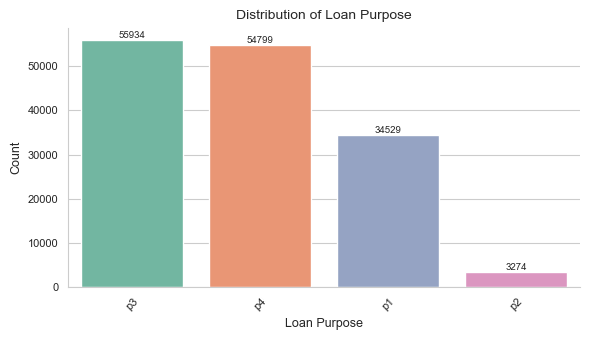

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 3.5))
ax = sns.countplot(x='loan_purpose', data=df, palette='Set2')

plt.title("Distribution of Loan Purpose", fontsize=10)
plt.xlabel("Loan Purpose", fontsize=9)
plt.ylabel("Count", fontsize=9)
plt.xticks(rotation=45, fontsize=8)
plt.yticks(fontsize=8)
sns.despine()

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.show()

C:\Users\harsh\AppData\Local\Temp\ipykernel_27196\3588278764.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='region', data=df, palette='Set3')


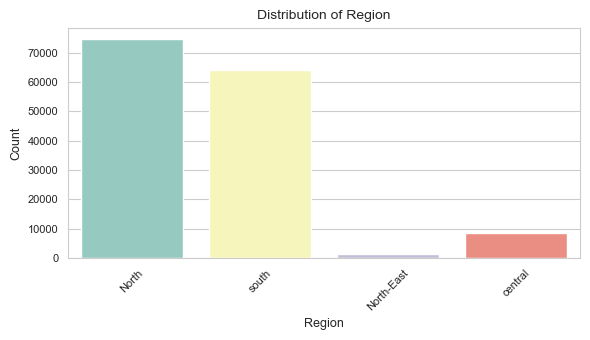

In [23]:
plt.figure(figsize=(6, 3.5))
sns.countplot(x='region', data=df, palette='Set3')
plt.title("Distribution of Region", fontsize=10)
plt.xlabel("Region", fontsize=9)
plt.ylabel("Count", fontsize=9)
plt.xticks(rotation=45, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

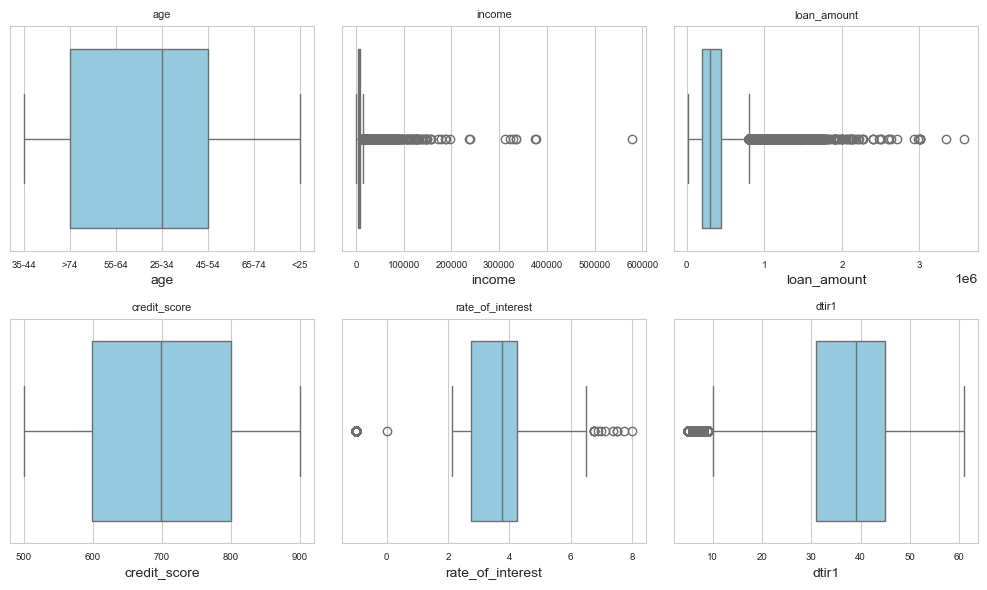

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ['age', 'income', 'loan_amount', 'credit_score', 'rate_of_interest', 'dtir1']

plt.figure(figsize=(10, 6))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(col, fontsize=8)
    plt.xticks(fontsize=7)

plt.tight_layout()
plt.show()

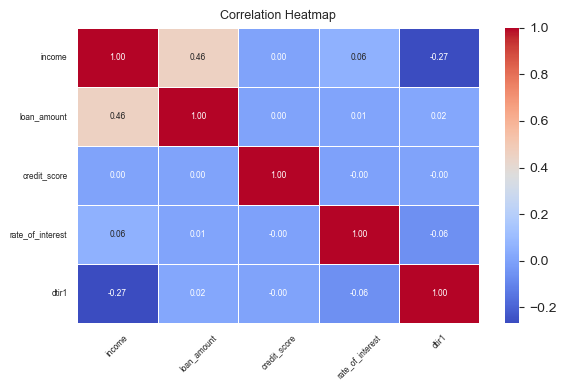

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_cols = ['income', 'loan_amount', 'credit_score', 'rate_of_interest', 'dtir1']

plt.figure(figsize=(6, 4))

sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    cbar_kws={"shrink": 1.0},
    linewidths=0.5,
    annot_kws={"size":6}
)

plt.title("Correlation Heatmap", fontsize=9)
plt.xticks(fontsize=6, rotation=45)
plt.yticks(fontsize=6)

plt.tight_layout()
plt.show()

In [34]:
target_corr = df[num_cols].corr()["status"].sort_values(ascending=False)

ValueError: could not convert string to float: '35-44'

In [31]:
age_map = {
    '<25': 1,
    '25-34': 2,
    '35-44': 3,
    '45-54': 4,
    '55-64': 5,
    '65-74': 6,
    '>74': 7
}

df['age_encoded'] = df['age'].map(age_map)

In [33]:
print(df[['age', 'age_encoded']].head())

     age  age_encoded
0  35-44          3.0
1    >74          7.0
2  55-64          5.0
3  35-44          3.0
4  35-44          3.0


In [35]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

le = LabelEncoder()

for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object':
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

In [15]:
print(df[num_cols].isnull().sum())

year                        0
loan_amount                 0
rate_of_interest            0
interest_rate_spread    36639
upfront_charges         39642
term                       41
property_value          15098
income                   9150
credit_score                0
ltv                     15098
status                      0
dtir1                   24121
high_interest_rate          0
senior_age                  0
dtype: int64


In [20]:
print(df[['interest_rate_spread', 'status']].isnull().sum())
print(df[['interest_rate_spread', 'status']].nunique())
print(df[['interest_rate_spread', 'status']].dtypes)

interest_rate_spread    36639
status                      0
dtype: int64
interest_rate_spread    22516
status                      2
dtype: int64
interest_rate_spread    float64
status                    int64
dtype: object


In [21]:
df = df.drop(columns=['interest_rate_spread'])

In [22]:
df.columns

Index(['Unnamed: 0', 'id', 'year', 'loan_limit', 'gender', 'approv_in_adv',
       'loan_type', 'loan_purpose', 'credit_worthiness', 'open_credit',
       'business_or_commercial', 'loan_amount', 'rate_of_interest',
       'upfront_charges', 'term', 'neg_ammortization', 'interest_only',
       'lump_sum_payment', 'property_value', 'construction_type',
       'occupancy_type', 'secured_by', 'total_units', 'income', 'credit_type',
       'credit_score', 'co-applicant_credit_type', 'age',
       'submission_of_application', 'ltv', 'region', 'security_type', 'status',
       'dtir1', 'high_interest_rate', 'senior_age'],
      dtype='object')

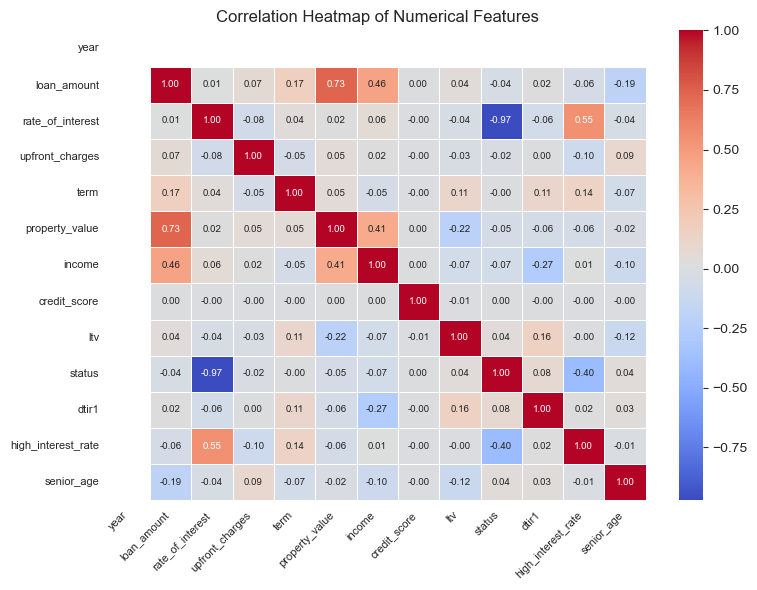

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = [
    'year', 'loan_amount', 'rate_of_interest',
    'upfront_charges', 'term', 'property_value', 'income',
    'credit_score', 'ltv', 'status', 'dtir1',
    'high_interest_rate', 'senior_age'
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    linewidths=0.5,
    annot_kws={"size":7}
)

plt.title("Correlation Heatmap of Numerical Features", fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)

plt.tight_layout()
plt.show()